
# UP-Fall Camera2 — Transformer Training

Notebook huấn luyện **Transformer Encoder** trên bộ skeleton đã tiền xử lý.

- Input: `(30, 51)`
- Dataset path:
  `/kaggle/input/datasets/anhoa1/upfall-camera2-processing`
- Train/Val/Test giữ nguyên subject split
- Không augmentation ở baseline Transformer
- Có `class_weight`
- Tune threshold trên validation theo **F2**
- Đánh giá: Accuracy, Precision, Recall, F1, F2, PR-AUC, ROC-AUC, Specificity, Confusion Matrix
- Lưu model `.keras`, threshold, metrics JSON, predictions CSV và thử export `.tflite`


In [1]:

# ============================================================
# 1. IMPORTS + REPRODUCIBILITY
# ============================================================

import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve,
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:

# ============================================================
# 2. CONFIG
# ============================================================

DATA_DIR = Path("/kaggle/input/datasets/anhoa1/upfall-camera2-processing")
OUTPUT_DIR = Path("/kaggle/working/upfall_transformer_baseline")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = DATA_DIR / "upfall_train.npz"
VAL_PATH   = DATA_DIR / "upfall_val.npz"
TEST_PATH  = DATA_DIR / "upfall_test.npz"
CLASS_WEIGHT_PATH = DATA_DIR / "class_weight.json"

SEQ_LEN = 30
NUM_FEATURES = 51

BATCH_SIZE = 128
EPOCHS = 100
INITIAL_LR = 1e-3

# Transformer
D_MODEL = 64
NUM_HEADS = 4
FF_DIM = 128
NUM_BLOCKS = 3
DROPOUT = 0.20

print("DATA_DIR exists:", DATA_DIR.exists())
for p in [TRAIN_PATH, VAL_PATH, TEST_PATH, CLASS_WEIGHT_PATH]:
    print(p.name, "->", p.exists())


DATA_DIR exists: True
upfall_train.npz -> True
upfall_val.npz -> True
upfall_test.npz -> True
class_weight.json -> True


In [3]:

# ============================================================
# 3. LOAD DATA
# ============================================================

def load_xy(path):
    d = np.load(path, allow_pickle=True)

    if "X" not in d.files or "y" not in d.files:
        raise KeyError(f"{path.name} thiếu X/y. Keys: {d.files}")

    X = d["X"].astype(np.float32)
    y = d["y"].astype(np.int32).reshape(-1)

    return X, y, d

X_train, y_train, train_npz = load_xy(TRAIN_PATH)
X_val, y_val, val_npz = load_xy(VAL_PATH)
X_test, y_test, test_npz = load_xy(TEST_PATH)

print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)


Train: (10407, 30, 51) (10407,)
Val  : (2046, 30, 51) (2046,)
Test : (4786, 30, 51) (4786,)


In [4]:

# ============================================================
# 4. VALIDATE DATA
# ============================================================

def check_split(name, X, y):
    print(f"\n{name}")
    print("Shape:", X.shape, y.shape)
    print("NaN:", int(np.isnan(X).sum()))
    print("Inf:", int(np.isinf(X).sum()))
    labels, counts = np.unique(y, return_counts=True)
    print("Labels:", dict(zip(labels.tolist(), counts.tolist())))

    assert X.shape[1:] == (SEQ_LEN, NUM_FEATURES)
    assert len(X) == len(y)
    assert np.isnan(X).sum() == 0
    assert np.isinf(X).sum() == 0
    assert set(np.unique(y)).issubset({0, 1})

check_split("TRAIN", X_train, y_train)
check_split("VAL", X_val, y_val)
check_split("TEST", X_test, y_test)

print("\nValidation PASSED.")



TRAIN
Shape: (10407, 30, 51) (10407,)
NaN: 0
Inf: 0
Labels: {0: 10093, 1: 314}

VAL
Shape: (2046, 30, 51) (2046,)
NaN: 0
Inf: 0
Labels: {0: 1990, 1: 56}

TEST
Shape: (4786, 30, 51) (4786,)
NaN: 0
Inf: 0
Labels: {0: 4686, 1: 100}

Validation PASSED.


In [5]:

# ============================================================
# 5. CLASS WEIGHT
# ============================================================

if CLASS_WEIGHT_PATH.exists():
    with open(CLASS_WEIGHT_PATH, "r", encoding="utf-8") as f:
        raw = json.load(f)

    class_weight = {
        int(k): float(v)
        for k, v in raw.items()
    }

else:
    n0 = int(np.sum(y_train == 0))
    n1 = int(np.sum(y_train == 1))
    n = len(y_train)

    class_weight = {
        0: n / (2.0 * n0),
        1: n / (2.0 * n1),
    }

print("Class weight:", class_weight)


Class weight: {0: 0.5155553353809571, 1: 16.571656050955415}



## Transformer architecture

Pipeline:

`(30,51) → Dense projection → Positional Embedding → Transformer Encoder × 3 → GlobalAveragePooling → Dense → Sigmoid`

Transformer dùng self-attention để học quan hệ chuyển động giữa các frame trong chuỗi 30 frame.


In [6]:

# ============================================================
# 6. POSITIONAL EMBEDDING
# ============================================================

class PositionalEmbedding(layers.Layer):
    def __init__(self, sequence_length, d_model, **kwargs):
        super().__init__(**kwargs)
        self.sequence_length = sequence_length
        self.d_model = d_model

        self.position_embeddings = layers.Embedding(
            input_dim=sequence_length,
            output_dim=d_model
        )

    def call(self, x):
        positions = tf.range(
            start=0,
            limit=self.sequence_length,
            delta=1
        )

        pos = self.position_embeddings(positions)

        return x + pos

    def get_config(self):
        config = super().get_config()
        config.update({
            "sequence_length": self.sequence_length,
            "d_model": self.d_model,
        })
        return config


In [7]:

# ============================================================
# 7. TRANSFORMER ENCODER BLOCK
# ============================================================

def transformer_encoder(
    x,
    d_model,
    num_heads,
    ff_dim,
    dropout
):
    # Multi-head self attention
    attn_output = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=d_model // num_heads,
        dropout=dropout
    )(x, x)

    attn_output = layers.Dropout(dropout)(attn_output)

    # Residual + LayerNorm
    x = layers.LayerNormalization(
        epsilon=1e-6
    )(x + attn_output)

    # Feed-forward network
    ff = layers.Dense(
        ff_dim,
        activation="gelu"
    )(x)

    ff = layers.Dropout(dropout)(ff)

    ff = layers.Dense(
        d_model
    )(ff)

    ff = layers.Dropout(dropout)(ff)

    # Residual + LayerNorm
    x = layers.LayerNormalization(
        epsilon=1e-6
    )(x + ff)

    return x


In [8]:

# ============================================================
# 8. BUILD TRANSFORMER MODEL
# ============================================================

tf.keras.backend.clear_session()

inputs = keras.Input(
    shape=(SEQ_LEN, NUM_FEATURES),
    name="skeleton_sequence"
)

# Feature projection
x = layers.Dense(
    D_MODEL,
    name="feature_projection"
)(inputs)

# Add learned positional embedding
x = PositionalEmbedding(
    sequence_length=SEQ_LEN,
    d_model=D_MODEL,
    name="positional_embedding"
)(x)

# Transformer blocks
for i in range(NUM_BLOCKS):
    x = transformer_encoder(
        x=x,
        d_model=D_MODEL,
        num_heads=NUM_HEADS,
        ff_dim=FF_DIM,
        dropout=DROPOUT
    )

# Sequence pooling
x = layers.GlobalAveragePooling1D()(x)

x = layers.Dense(
    64,
    activation="gelu"
)(x)

x = layers.Dropout(0.30)(x)

x = layers.Dense(
    32,
    activation="gelu"
)(x)

x = layers.Dropout(0.20)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="fall_probability"
)(x)

model = keras.Model(
    inputs,
    outputs,
    name="upfall_transformer_baseline"
)

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=INITIAL_LR
    ),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="roc_auc"),
        keras.metrics.AUC(
            curve="PR",
            name="pr_auc"
        ),
    ],
)

model.summary()


I0000 00:00:1792416878.764549      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792416878.768593      50 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "upfall_transformer_baseline"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ skeleton_sequence   │ (None, 30, 51)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_projection  │ (None, 30, 64)    │      3,328 │ skeleton_sequenc… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, 30, 64)    │      1,920 │ feature_projecti… │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 30, 64)    │     16,640 │ positional_embed… │
│ (MultiHeadAttentio… │                   │            │ positional_embed… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 30, 64)    │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 30, 64)    │          0 │ positional_embed… │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 30, 64)    │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 30, 128)   │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 30, 128)   │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 30, 64)    │      8,256 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 30, 64)    │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 30, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 64)    │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 30, 64)    │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 30, 64)    │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 30, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 30, 64)    │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 30, 128)   │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 30, 128)   │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 111,937 (437.25 KB)

 Trainable params: 111,937 (437.25 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:

# ============================================================
# 9. CALLBACKS
# ============================================================

BEST_MODEL_PATH = (
    OUTPUT_DIR /
    "best_transformer_baseline.keras"
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=BEST_MODEL_PATH,
        monitor="val_pr_auc",
        mode="max",
        save_best_only=True,
        verbose=1,
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_pr_auc",
        mode="max",
        patience=15,
        restore_best_weights=True,
        verbose=1,
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=6,
        min_lr=1e-6,
        verbose=1,
    ),
]


In [10]:

# ============================================================
# 10. TRAIN TRANSFORMER
# ============================================================

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1,
)

print("Training finished.")
print("Best model:", BEST_MODEL_PATH)


Epoch 1/100
15/82 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6579 - loss: 0.6713 - pr_auc: 0.0436 - precision: 0.0446 - recall: 0.5009 - roc_auc: 0.6175

I0000 00:00:1792416902.595031     143 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step - accuracy: 0.7655 - loss: 0.5338 - pr_auc: 0.1859 - precision: 0.0902 - recall: 0.6859 - roc_auc: 0.7902
Epoch 1: val_pr_auc improved from None to 0.61091, saving model to /kaggle/working/upfall_transformer_baseline/best_transformer_baseline.keras

Epoch 1: finished saving model to /kaggle/working/upfall_transformer_baseline/best_transformer_baseline.keras
82/82 ━━━━━━━━━━━━━━━━━━━━ 40s 232ms/step - accuracy: 0.8439 - loss: 0.3980 - pr_auc: 0.3555 - precision: 0.1400 - recall: 0.8121 - roc_auc: 0.9039 - val_accuracy: 0.9003 - val_loss: 0.2911 - val_pr_auc: 0.6109 - val_precision: 0.2016 - val_recall: 0.8929 - val_roc_auc: 0.9651 - learning_rate: 0.0010
Epoch 2/100
78/82 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9230 - loss: 0.2105 - pr_auc: 0.5705 - precision: 0.2698 - recall: 0.9243 - roc_auc: 0.9698
Epoch 2: val_pr_auc did not improve from 0.61091
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9262 - loss: 0.2160 - pr_auc: 0.5254 

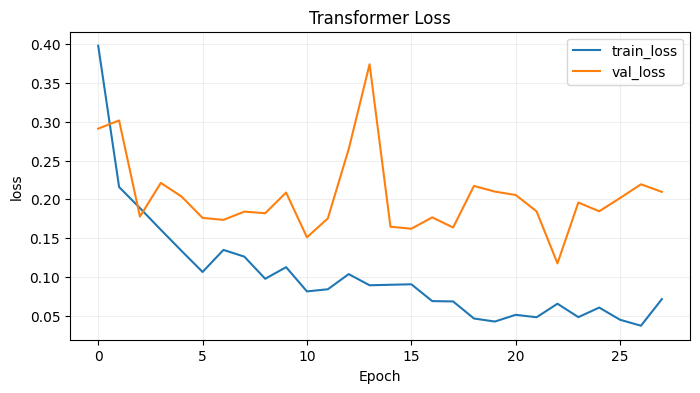

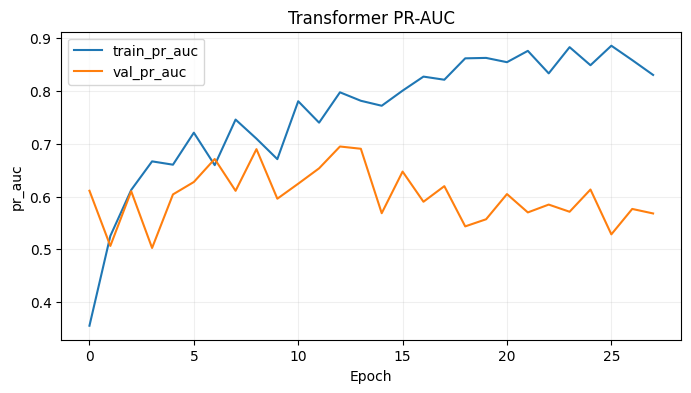

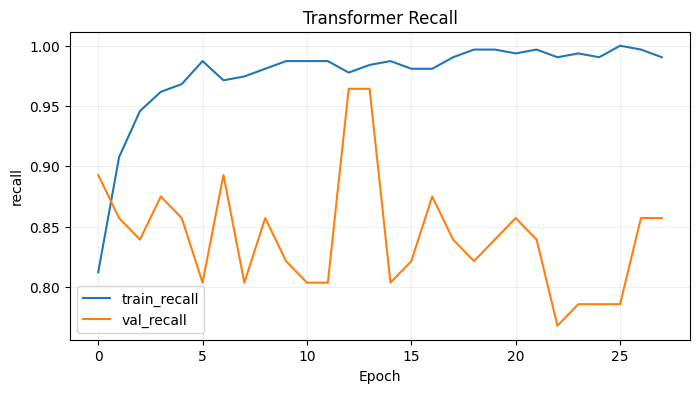

In [11]:

# ============================================================
# 11. TRAINING CURVES
# ============================================================

history_df = pd.DataFrame(history.history)

history_df.to_csv(
    OUTPUT_DIR / "training_history.csv",
    index=False
)

def plot_history(metric, title):
    plt.figure(figsize=(8, 4))

    plt.plot(
        history_df[metric],
        label=f"train_{metric}"
    )

    val_metric = f"val_{metric}"

    if val_metric in history_df.columns:
        plt.plot(
            history_df[val_metric],
            label=val_metric
        )

    plt.xlabel("Epoch")
    plt.ylabel(metric)
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

plot_history("loss", "Transformer Loss")
plot_history("pr_auc", "Transformer PR-AUC")
plot_history("recall", "Transformer Recall")


In [12]:

# ============================================================
# 12. LOAD BEST MODEL
# ============================================================

model = keras.models.load_model(
    BEST_MODEL_PATH,
    custom_objects={
        "PositionalEmbedding": PositionalEmbedding
    }
)

val_prob = model.predict(
    X_val,
    batch_size=BATCH_SIZE,
    verbose=0
).reshape(-1)

print(
    "Validation probabilities:",
    val_prob.shape
)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'positional_embedding', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Validation probabilities: (2046,)


In [13]:

# ============================================================
# 13. THRESHOLD TUNING ON VALIDATION
# ============================================================

rows = []

for threshold in np.arange(
    0.05,
    0.951,
    0.01
):
    pred = (
        val_prob >= threshold
    ).astype(np.int32)

    precision = precision_score(
        y_val,
        pred,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        pred,
        zero_division=0
    )

    f2 = fbeta_score(
        y_val,
        pred,
        beta=2,
        zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        pred,
        labels=[0, 1]
    ).ravel()

    rows.append({
        "threshold": float(threshold),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "f2": float(f2),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    })

threshold_df = pd.DataFrame(rows)

best_row = (
    threshold_df
    .sort_values(
        ["f2", "recall", "precision"],
        ascending=False
    )
    .iloc[0]
)

BEST_THRESHOLD = float(
    best_row["threshold"]
)

print(
    "Best threshold by validation F2:",
    BEST_THRESHOLD
)

display(
    best_row.to_frame().T
)

threshold_df.to_csv(
    OUTPUT_DIR /
    "validation_threshold_search.csv",
    index=False
)

with open(
    OUTPUT_DIR / "best_threshold.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        {
            "criterion": "max_validation_f2",
            "threshold": BEST_THRESHOLD,
            "validation_metrics": {
                k: (
                    int(v)
                    if k in {"tn", "fp", "fn", "tp"}
                    else float(v)
                )
                for k, v
                in best_row.to_dict().items()
            },
        },
        f,
        indent=2
    )


Best threshold by validation F2: 0.9500000000000002


,threshold,precision,recall,f1,f2,tn,fp,fn,tp
90,0.95,0.672131,0.732143,0.700855,0.719298,1970.0,20.0,15.0,41.0


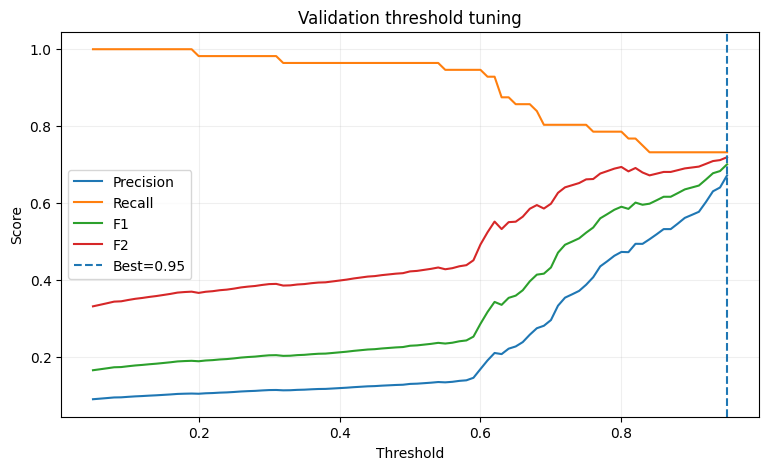

In [14]:

# ============================================================
# 14. THRESHOLD CURVES
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    label="F1"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f2"],
    label="F2"
)

plt.axvline(
    BEST_THRESHOLD,
    linestyle="--",
    label=f"Best={BEST_THRESHOLD:.2f}"
)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Validation threshold tuning")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


In [15]:

# ============================================================
# 15. EVALUATION FUNCTION
# ============================================================

def evaluate_binary(
    y_true,
    prob,
    threshold
):
    pred = (
        prob >= threshold
    ).astype(np.int32)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        pred,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    metrics = {
        "threshold": float(threshold),

        "accuracy": float(
            accuracy_score(
                y_true,
                pred
            )
        ),

        "precision": float(
            precision_score(
                y_true,
                pred,
                zero_division=0
            )
        ),

        "recall": float(
            recall_score(
                y_true,
                pred,
                zero_division=0
            )
        ),

        "specificity": float(
            specificity
        ),

        "f1": float(
            f1_score(
                y_true,
                pred,
                zero_division=0
            )
        ),

        "f2": float(
            fbeta_score(
                y_true,
                pred,
                beta=2,
                zero_division=0
            )
        ),

        "roc_auc": float(
            roc_auc_score(
                y_true,
                prob
            )
        ),

        "pr_auc": float(
            average_precision_score(
                y_true,
                prob
            )
        ),

        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }

    return metrics, pred


In [16]:

# ============================================================
# 16. FINAL TEST
# ============================================================

test_prob = model.predict(
    X_test,
    batch_size=BATCH_SIZE,
    verbose=0
).reshape(-1)

test_metrics, test_pred = (
    evaluate_binary(
        y_test,
        test_prob,
        BEST_THRESHOLD
    )
)

print("FINAL TRANSFORMER TEST METRICS")
print("=" * 60)

for k, v in test_metrics.items():

    if isinstance(v, float):
        print(
            f"{k:12s}: {v:.6f}"
        )

    else:
        print(
            f"{k:12s}: {v}"
        )

print("\nClassification report:")

print(
    classification_report(
        y_test,
        test_pred,
        target_names=[
            "No Fall",
            "Fall"
        ],
        digits=4,
        zero_division=0
    )
)

with open(
    OUTPUT_DIR / "test_metrics.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        test_metrics,
        f,
        indent=2
    )


FINAL TRANSFORMER TEST METRICS
threshold   : 0.950000
accuracy    : 0.983911
precision   : 0.595041
recall      : 0.720000
specificity : 0.989543
f1          : 0.651584
f2          : 0.690979
roc_auc     : 0.979494
pr_auc      : 0.618362
tn          : 4637
fp          : 49
fn          : 28
tp          : 72

Classification report:
              precision    recall  f1-score   support

     No Fall     0.9940    0.9895    0.9918      4686
        Fall     0.5950    0.7200    0.6516       100

    accuracy                         0.9839      4786
   macro avg     0.7945    0.8548    0.8217      4786
weighted avg     0.9857    0.9839    0.9847      4786



[[4637   49]
 [  28   72]]


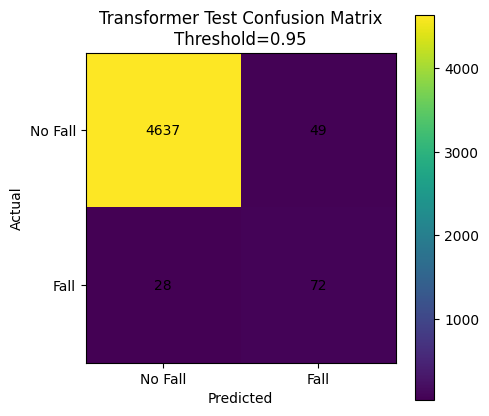

Fall thật: 100
TP: 72
FN (Fall -> No Fall): 28


In [17]:

# ============================================================
# 17. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
)

print(cm)

fig, ax = plt.subplots(
    figsize=(5, 5)
)

im = ax.imshow(cm)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(
    ["No Fall", "Fall"]
)

ax.set_yticklabels(
    ["No Fall", "Fall"]
)

ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")

ax.set_title(
    "Transformer Test Confusion Matrix\n"
    f"Threshold={BEST_THRESHOLD:.2f}"
)

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center"
        )

plt.colorbar(im)
plt.show()

print(
    "Fall thật:",
    int(np.sum(y_test == 1))
)

print(
    "TP:",
    test_metrics["tp"]
)

print(
    "FN (Fall -> No Fall):",
    test_metrics["fn"]
)


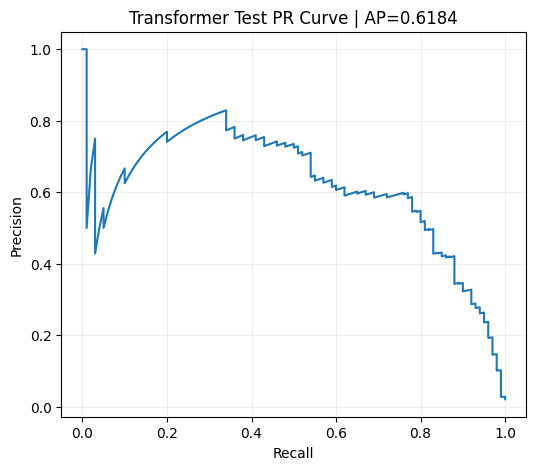

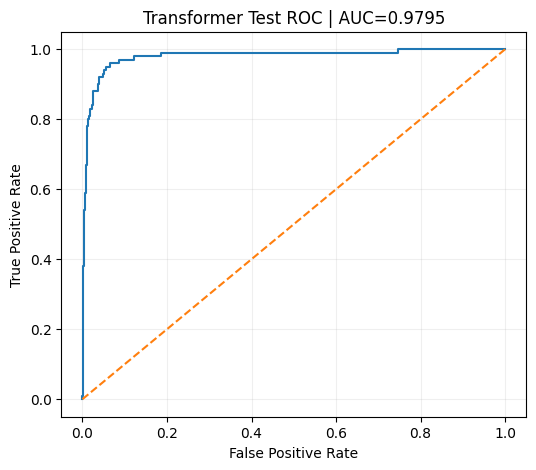

In [18]:

# ============================================================
# 18. PR + ROC CURVES
# ============================================================

precision_curve, recall_curve, _ = (
    precision_recall_curve(
        y_test,
        test_prob
    )
)

plt.figure(figsize=(6, 5))

plt.plot(
    recall_curve,
    precision_curve
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Transformer Test PR Curve | "
    f"AP={test_metrics['pr_auc']:.4f}"
)

plt.grid(alpha=0.2)
plt.show()


fpr, tpr, _ = roc_curve(
    y_test,
    test_prob
)

plt.figure(figsize=(6, 5))

plt.plot(
    fpr,
    tpr
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "Transformer Test ROC | "
    f"AUC={test_metrics['roc_auc']:.4f}"
)

plt.grid(alpha=0.2)
plt.show()


In [19]:

# ============================================================
# 19. SAVE TEST PREDICTIONS
# ============================================================

pred_df = pd.DataFrame({
    "y_true": y_test.astype(int),
    "prob_fall": test_prob.astype(float),
    "y_pred": test_pred.astype(int),
})

for key in [
    "subject",
    "activity",
    "trial"
]:
    if key in test_npz.files:
        pred_df[key] = test_npz[key]

pred_df["error_type"] = "correct"

pred_df.loc[
    (
        (pred_df["y_true"] == 1)
        &
        (pred_df["y_pred"] == 0)
    ),
    "error_type"
] = "FN_fall_missed"

pred_df.loc[
    (
        (pred_df["y_true"] == 0)
        &
        (pred_df["y_pred"] == 1)
    ),
    "error_type"
] = "FP_false_alarm"

pred_path = (
    OUTPUT_DIR /
    "test_predictions.csv"
)

pred_df.to_csv(
    pred_path,
    index=False
)

print("Saved:", pred_path)

print(
    pred_df["error_type"]
    .value_counts()
)


Saved: /kaggle/working/upfall_transformer_baseline/test_predictions.csv
error_type
correct           4709
FP_false_alarm      49
FN_fall_missed      28
Name: count, dtype: int64


In [20]:

# ============================================================
# 20. FALL RECALL BY ACTIVITY
# ============================================================

if "activity" in pred_df.columns:

    fall_only = pred_df[
        pred_df["y_true"] == 1
    ].copy()

    activity_eval = (
        fall_only
        .groupby("activity")
        .agg(
            total_fall=("y_true", "size"),
            detected_fall=("y_pred", "sum")
        )
        .reset_index()
    )

    activity_eval["missed_fall"] = (
        activity_eval["total_fall"]
        -
        activity_eval["detected_fall"]
    )

    activity_eval["recall"] = (
        activity_eval["detected_fall"]
        /
        activity_eval["total_fall"]
    )

    display(
        activity_eval
    )

    activity_eval.to_csv(
        OUTPUT_DIR /
        "fall_recall_by_activity.csv",
        index=False
    )

else:
    print(
        "Test NPZ không có activity metadata."
    )


,activity,total_fall,detected_fall,missed_fall,recall
0,1,20,16,4,0.800000
1,2,21,16,5,0.761905
2,3,18,14,4,0.777778
3,4,16,11,5,0.687500
4,5,25,15,10,0.600000


In [21]:

# ============================================================
# 21. EXPORT KERAS + TFLITE
# ============================================================

FINAL_KERAS_PATH = (
    OUTPUT_DIR /
    "transformer_baseline_final.keras"
)

model.save(
    FINAL_KERAS_PATH
)

print(
    "Saved:",
    FINAL_KERAS_PATH
)

converter = (
    tf.lite.TFLiteConverter
    .from_keras_model(model)
)

try:
    tflite_model = (
        converter.convert()
    )

    TFLITE_PATH = (
        OUTPUT_DIR /
        "transformer_baseline.tflite"
    )

    with open(
        TFLITE_PATH,
        "wb"
    ) as f:
        f.write(
            tflite_model
        )

    print(
        "Saved TFLite:",
        TFLITE_PATH
    )

    print(
        "Size MB:",
        TFLITE_PATH.stat().st_size
        / 1024 / 1024
    )

except Exception as e:
    print(
        "TFLite export failed:",
        type(e).__name__,
        e
    )


Saved: /kaggle/working/upfall_transformer_baseline/transformer_baseline_final.keras
INFO:tensorflow:Assets written to: /tmp/tmpmud6da2s/assets


INFO:tensorflow:Assets written to: /tmp/tmpmud6da2s/assets


Saved artifact at '/tmp/tmpmud6da2s'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 30, 51), dtype=tf.float32, name='skeleton_sequence')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  135818883611728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135818883612112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135818882278480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135818884510160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135818882616208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135818882618128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135818882621968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135818882616016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135818883608080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135818883610000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13581888359656

W0000 00:00:1792416953.927482      50 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792416953.927504      50 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1792416953.963378      50 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled


In [22]:

# ============================================================
# 22. FINAL EXPERIMENT SUMMARY
# ============================================================

summary = {
    "model": "Transformer baseline",

    "input_shape": [
        SEQ_LEN,
        NUM_FEATURES
    ],

    "architecture": {
        "d_model": D_MODEL,
        "num_heads": NUM_HEADS,
        "ff_dim": FF_DIM,
        "num_blocks": NUM_BLOCKS,
        "dropout": DROPOUT,
    },

    "train_samples": int(
        len(X_train)
    ),

    "val_samples": int(
        len(X_val)
    ),

    "test_samples": int(
        len(X_test)
    ),

    "train_fall": int(
        np.sum(y_train == 1)
    ),

    "val_fall": int(
        np.sum(y_val == 1)
    ),

    "test_fall": int(
        np.sum(y_test == 1)
    ),

    "class_weight": {
        str(k): float(v)
        for k, v
        in class_weight.items()
    },

    "best_threshold": float(
        BEST_THRESHOLD
    ),

    "test_metrics": (
        test_metrics
    ),
}

with open(
    OUTPUT_DIR /
    "experiment_summary.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        summary,
        f,
        indent=2
    )

print(
    json.dumps(
        summary,
        indent=2
    )
)

print("\nOUTPUT FILES")
print("=" * 60)

for p in sorted(
    OUTPUT_DIR.iterdir()
):
    print(
        f"{p.name:40s}",
        f"{p.stat().st_size / 1024 / 1024:.2f} MB"
    )


{
  "model": "Transformer baseline",
  "input_shape": [
    30,
    51
  ],
  "architecture": {
    "d_model": 64,
    "num_heads": 4,
    "ff_dim": 128,
    "num_blocks": 3,
    "dropout": 0.2
  },
  "train_samples": 10407,
  "val_samples": 2046,
  "test_samples": 4786,
  "train_fall": 314,
  "val_fall": 56,
  "test_fall": 100,
  "class_weight": {
    "0": 0.5155553353809571,
    "1": 16.571656050955415
  },
  "best_threshold": 0.9500000000000002,
  "test_metrics": {
    "threshold": 0.9500000000000002,
    "accuracy": 0.9839114082741329,
    "precision": 0.5950413223140496,
    "recall": 0.72,
    "specificity": 0.989543320529236,
    "f1": 0.6515837104072398,
    "f2": 0.690978886756238,
    "roc_auc": 0.97949423815621,
    "pr_auc": 0.6183620096222473,
    "tn": 4637,
    "fp": 49,
    "fn": 28,
    "tp": 72
  }
}

OUTPUT FILES
best_threshold.json                      0.00 MB
best_transformer_baseline.keras          1.48 MB
experiment_summary.json                  0.00 MB
fall_reca


## Sau khi chạy xong

Ưu tiên xem:

- `Recall`
- `F2`
- `PR-AUC`
- `FN`
- `fall_recall_by_activity.csv`

Sau đó so trực tiếp Transformer với LSTM trên **cùng test set**.

Không chọn model chỉ theo Accuracy vì dữ liệu No Fall chiếm đa số.


## Local deployment bundle
Cell cuối lưu model, TFLite, threshold, config và ví dụ inference thành một ZIP.

In [23]:

# ============================================================
# LOCAL DEPLOYMENT EXPORT
# ============================================================

import json, shutil
from pathlib import Path

DEPLOY_DIR = OUTPUT_DIR / "deploy_bundle"
DEPLOY_DIR.mkdir(parents=True, exist_ok=True)

artifact_names = [
    "best_transformer_baseline.keras",
    "transformer_baseline_final.keras",
    "transformer_baseline.tflite",
    "best_threshold.json",
    "experiment_summary.json",
    "test_metrics.json",
]

for name in artifact_names:
    src = OUTPUT_DIR / name
    if src.exists():
        shutil.copy2(src, DEPLOY_DIR / name)

deployment_config = {
    "model_name": "Transformer baseline",
    "input_shape": [30, 51],
    "sequence_length": 30,
    "num_keypoints": 17,
    "feature_order_per_keypoint": ["x", "y", "visibility"],
    "keypoint_names": ['nose', 'left_shoulder', 'right_shoulder', 'left_elbow', 'right_elbow', 'left_wrist', 'right_wrist', 'left_hip', 'right_hip', 'left_knee', 'right_knee', 'left_ankle', 'right_ankle', 'left_heel', 'right_heel', 'left_foot_index', 'right_foot_index'],
    "label_mapping": {"0": "No Fall", "1": "Fall"},
    "threshold": float(BEST_THRESHOLD),
    "threshold_source": "validation max F2",
    "input_dtype": "float32",
    "output": "Fall probability",
    "preprocessing_contract": [
        "Use the same MediaPipe 17-keypoint mapping as training preprocessing.",
        "Use the same missing-data interpolation as training preprocessing.",
        "Use the exact same normalize_skeleton() used to build the NPZ dataset.",
        "Do not add a new scaler unless training used it.",
        "Feed exactly 30 consecutive preprocessed frames.",
        "Apply the saved threshold to the Fall probability."
    ]
}

with open(DEPLOY_DIR / "deployment_config.json", "w", encoding="utf-8") as f:
    json.dump(deployment_config, f, indent=2, ensure_ascii=False)

inference_py = """import json
import numpy as np
import tensorflow as tf
from pathlib import Path

HERE = Path(__file__).resolve().parent
cfg = json.load(open(HERE / "deployment_config.json", "r", encoding="utf-8"))
threshold = float(cfg["threshold"])

model_path = next(HERE.glob("*.tflite"))
interpreter = tf.lite.Interpreter(model_path=str(model_path))
interpreter.allocate_tensors()

inp = interpreter.get_input_details()[0]
out = interpreter.get_output_details()[0]

def predict_preprocessed(sequence_30x51):
    x = np.asarray(sequence_30x51, dtype=np.float32)
    if x.shape != (30, 51):
        raise ValueError(f"Expected (30,51), got {x.shape}")
    interpreter.set_tensor(inp["index"], x[None, ...])
    interpreter.invoke()
    prob = float(interpreter.get_tensor(out["index"]).reshape(-1)[0])
    label = int(prob >= threshold)
    return {
        "prob_fall": prob,
        "label": label,
        "class_name": "Fall" if label else "No Fall",
    }
"""

with open(DEPLOY_DIR / "inference_tflite_example.py", "w", encoding="utf-8") as f:
    f.write(inference_py)

readme = f"""UP-Fall local deployment bundle
Model: {deployment_config['model_name']}
Input: (30,51) float32
Threshold: {deployment_config['threshold']}

Use the .tflite file for lightweight local inference.
Use .keras if you want TensorFlow/Keras inference or further fine-tuning.

IMPORTANT:
For raw webcam/video, reproduce the exact preprocessing used for the NPZ:
MediaPipe -> 17 keypoints -> interpolation -> exact normalize_skeleton()
-> rolling 30-frame buffer -> model -> threshold.
"""

with open(DEPLOY_DIR / "README_DEPLOY.txt", "w", encoding="utf-8") as f:
    f.write(readme)

DEPLOY_ZIP = OUTPUT_DIR / "upfall_transformer_baseline_LOCAL_DEPLOY.zip"
shutil.make_archive(
    str(DEPLOY_ZIP.with_suffix("")),
    "zip",
    root_dir=DEPLOY_DIR
)

print("DEPLOY ZIP:", DEPLOY_ZIP)
print("FILES:")
for p in sorted(DEPLOY_DIR.iterdir()):
    print(" -", p.name)


DEPLOY ZIP: /kaggle/working/upfall_transformer_baseline/upfall_transformer_baseline_LOCAL_DEPLOY.zip
FILES:
 - README_DEPLOY.txt
 - best_threshold.json
 - best_transformer_baseline.keras
 - deployment_config.json
 - experiment_summary.json
 - inference_tflite_example.py
 - test_metrics.json
 - transformer_baseline.tflite
 - transformer_baseline_final.keras
